In [113]:
from trx import loadmat, to_py, load_trx
import TrkFile
import matplotlib.pyplot as plt
import numpy as np


BASE_DIR = "/groups/branson/bransonlab/flybubble_social/aggression2025/EmptySS/20230615T074558_rig1_flyBubble1_SSempty_72C11LexAivk5LexAopTrpAVIE260UASGtACR_20230419_AggAVLPGtACR"

In [114]:
trx, _ = loadmat(f"{BASE_DIR}/registered_trx.mat")

In [115]:
aggression_scores, _ = loadmat(f"{BASE_DIR}/scores_FeAggfRGBub.mat")

In [116]:
indicator_mat, _ = loadmat(f"{BASE_DIR}/indicatordata.mat")

In [117]:
indicator_data = indicator_mat['indicatorLED'][0, 0].indicatordigital[0].astype(int)

In [118]:
allScores = aggression_scores['allScores'][0, 0]

## Plotting Aggression Scores for a Fly

In [119]:
def plot_fly_scores(fly_idx):
    """
    Plot aggression scores for a specific fly with color-coded patches.
    
    Parameters:
    -----------
    fly_idx : int
        Index of the fly to plot
    """
    flyStart = allScores.tStart[0, fly_idx].astype(int) - 1
    flyEnd = allScores.tEnd[0, fly_idx].astype(int) - 1
    flyScores = allScores.scores[0, fly_idx][0]
    flyProcessedScores = allScores.postprocessed[0, fly_idx][0]
    fly_trx = trx['trx'][0, fly_idx]
    
    fig, ax = plt.subplots(figsize=(12, 4))
    
    # Get data slices
    fly_indicator = indicator_data[flyStart:flyEnd + 1]
    fly_scores_slice = flyScores[flyStart:flyEnd + 1]
    fly_processed_slice = flyProcessedScores[flyStart:flyEnd + 1]
    
    # Calculate min and max values for patch height
    maxval = fly_scores_slice.max() * 1.1
    minval = fly_scores_slice.min() * 1.1
    
    # Create masks for different regions
    indicator_only = (fly_indicator == 1) & (fly_processed_slice != 1)
    processed_only = (fly_processed_slice == 1) & (fly_indicator != 1)
    both_active = (fly_indicator == 1) & (fly_processed_slice == 1)
    
    # Helper function to draw patches
    def draw_patches(mask, color, label):
        mask_diff = np.diff(np.concatenate(([0], mask.astype(int), [0])))
        starts = np.where(mask_diff == 1)[0]
        ends = np.where(mask_diff == -1)[0]
        for i, (start, end) in enumerate(zip(starts, ends)):
            rect = plt.matplotlib.patches.Rectangle((start, minval), end - start, maxval - minval,
                                                   facecolor=color, alpha=0.3, 
                                                   label=label if i == 0 else '')
            ax.add_patch(rect)
    
    # Draw patches for each condition with distinct colors
    draw_patches(processed_only, 'orange', 'Processed (Aggression only)')
    draw_patches(indicator_only, 'cyan', 'Indicator only')
    draw_patches(both_active, 'magenta', 'Both Indicator & Aggression')
    
    # Plot raw scores
    ax.plot(fly_scores_slice, label='Raw Scores', alpha=0.7, color='black', linewidth=1.5)
    
    ax.set_xlabel('Frame')
    ax.set_ylabel('Aggression Score')
    ax.set_title(f'Aggression Scores for Fly {fly_idx}')
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

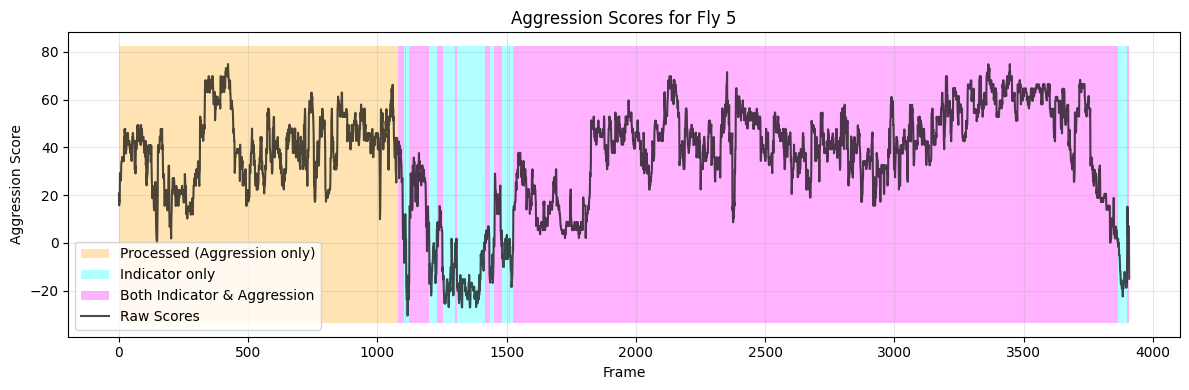

In [120]:
# Example usage
plot_fly_scores(5)